In [1]:
PROJECT_RANDOM_STATE = 2627
print("PROJECT_RANDOM_STATE =", PROJECT_RANDOM_STATE)

PROJECT_RANDOM_STATE = 2627


# Practice 3 — Challenge B: linear regression, Ridge and Lasso (R3)

**Scope:** P3.3, P3.4 and the Challenge B part of P3.5.

## Setup from R1 and R4

Paste here the cells published by R1 and R4. They are **not** pasted into the final notebook.

Cells from R4 (Claudia), copied without changes: fold reading, grouping check and data loading.

In [2]:
import numpy as np
import pandas as pd

In [3]:
CV_FOLDS = 5   # K, the number of canonical folds


def canonical_cv(challenge, dev):
    """Read the course fold file and return the folds as (train_idx, val_idx) pairs."""
    fold_table = pd.read_csv("../folds/" + challenge + "_folds.csv")

    # The positions only make sense if both files list the rows in the same order
    same_order = np.array_equal(fold_table["row_id"].to_numpy(), dev["row_id"].to_numpy())
    assert same_order, "the fold file and the data table list the rows in a different order"

    fold_id = fold_table["fold_id"].to_numpy()
    folds = []
    for f in range(CV_FOLDS):
        train_idx = np.where(fold_id != f)[0]   # rows of the other four folds
        val_idx = np.where(fold_id == f)[0]     # rows of fold f
        folds.append((train_idx, val_idx))
    return folds

In [4]:
def check_folds(folds, groups):
    """Check that no group is split between training and validation, fold by fold."""
    groups = np.asarray(groups)
    times_validated = np.zeros(len(groups), dtype=int)

    for number, (train_idx, val_idx) in enumerate(folds, start=1):
        shared = set(groups[train_idx]) & set(groups[val_idx])
        print(f"fold {number}: {len(train_idx)} training rows, {len(val_idx)} validation rows, "
              f"{len(shared)} groups in both parts")
        assert len(shared) == 0, "a group is in training and in validation"
        times_validated[val_idx] = times_validated[val_idx] + 1

    # Every row must be in the validation part of exactly one fold
    assert (times_validated == 1).all(), "a row is not validated exactly once"
    print("every row is validated exactly once")


def mean_and_spread(values):
    """Mean and spread (max - min) of the five fold values."""
    values = np.asarray(values, dtype=float)
    return values.mean(), values.max() - values.min()

In [5]:
# Only for this draft notebook: in p3_storage.ipynb these names come from R1's cells
dev = pd.read_csv("../datos/storage/storage_development.csv")
groups = pd.read_csv("../datos/storage/storage_groups.csv")

NOMINAL = ["load_type", "io_type", "raid", "device_type"]
NUMERIC = ["block_size", "n_jobs", "iodepth", "read_fraction", "n_disks"]
FEATURES = NOMINAL + NUMERIC

X = dev[FEATURES]                         # only the 9 source predictors
latency_ns = dev["latency_ns"].to_numpy()
z = np.log10(latency_ns)                  # modelling target, z = log10(latency_ns)

In [6]:
# The groups file must list the rows in the same order as the data table
assert np.array_equal(groups["row_id"].to_numpy(), dev["row_id"].to_numpy())

folds = canonical_cv("storage", dev)

In [7]:
# Grouping rule: no config_group may be in training and in validation of the same fold
check_folds(folds, groups["config_group"])

# X must only hold the source predictors: never row_id, feature_group, config_group or fold_id
assert list(X.columns) == FEATURES

fold 1: 9750 training rows, 2440 validation rows, 0 groups in both parts
fold 2: 9750 training rows, 2440 validation rows, 0 groups in both parts
fold 3: 9750 training rows, 2440 validation rows, 0 groups in both parts
fold 4: 9755 training rows, 2435 validation rows, 0 groups in both parts
fold 5: 9755 training rows, 2435 validation rows, 0 groups in both parts
every row is validated exactly once


In [8]:
#TEMPORARY CELL preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# same order as NOMINAL
REFERENCE_LEVELS = ["random", "write", "4+1", "nvme"]

def make_preprocessor():
    encoder = OneHotEncoder(drop=REFERENCE_LEVELS, handle_unknown="ignore", sparse_output=False)
    scaler = StandardScaler()
    preprocessor = ColumnTransformer([("num", scaler, NUMERIC), ("cat", encoder, NOMINAL)])
    return preprocessor

# P3.3 — Linear regression

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [10]:
mae_list = []
rmse_list = []
r2_list = []
mae_ns_list = []
coef_list = []

for train_idx, val_idx in folds:
    # the preprocessor is fitted inside the fold, on training rows only
    model = Pipeline([("prep", make_preprocessor()), ("reg", LinearRegression())]) #declare model with preprocessing function and type (regression)
    model.fit(X.iloc[train_idx], z[train_idx]) #train the model

    z_pred = model.predict(X.iloc[val_idx]) #obtain the prediction for the validation data
    z_true = z[val_idx] #obtain the validation true values on those same rows

    mae_list.append(mean_absolute_error(z_true, z_pred))
    rmse_list.append(np.sqrt(mean_squared_error(z_true, z_pred)))
    r2_list.append(r2_score(z_true, z_pred))
    # back to nanoseconds first, then the error
    mae_ns_list.append(mean_absolute_error(latency_ns[val_idx], 10 ** z_pred))
    coef_list.append(model.named_steps["reg"].coef_)

In [11]:
print("MAE(z) per fold:", np.round(mae_list, 4))
print("MAE(z) mean:", round(np.mean(mae_list), 4), "std:", round(np.std(mae_list), 4))
print("RMSE(z) mean:", round(np.mean(rmse_list), 4))
print("R2(z) mean:", round(np.mean(r2_list), 4))
print("MAE_ns mean:", round(np.mean(mae_ns_list)))

MAE(z) per fold: [0.2047 0.1937 0.1984 0.1953 0.1987]
MAE(z) mean: 0.1981 std: 0.0038
RMSE(z) mean: 0.2703
R2(z) mean: 0.8964
MAE_ns mean: 16289769


**Interpretation.** 
The mean MAE(z) is 0.1981, so predictions are off by a factor of about 10^0.1981 ≈ 1.58 on a typical row. R²(z) is 0.8964. The MAE of about 16.3 million ns was computed after inverting predictions with 10^z. It is dominated by the slowest configurations, so it does not replace the error on z.

In [12]:
#here we show the coefficients (weight) of each variable in each fold
names = model.named_steps["prep"].get_feature_names_out()
coef_table = pd.DataFrame(coef_list, columns=names)
print(coef_table.T.round(4))
summary = pd.DataFrame({"mean coef": coef_table.mean(), "factor": 10 ** coef_table.mean()})
print(summary.round(4))

                                0       1       2       3       4
num__block_size            0.2569  0.2484  0.2585  0.2577  0.2625
num__n_jobs                0.2586  0.2552  0.2518  0.2555  0.2566
num__iodepth               0.2653  0.2655  0.2633  0.2570  0.2677
num__read_fraction        -0.0570 -0.0542 -0.0571 -0.0613 -0.0545
num__n_disks              -0.0828 -0.0787 -0.0775 -0.0825 -0.0793
cat__load_type_sequential  0.5442  0.5667  0.5425  0.5165  0.5466
cat__io_type_read         -0.1977 -0.1925 -0.1999 -0.2053 -0.1891
cat__raid_1+1              0.0062  0.0067  0.0001  0.0114  0.0095
cat__raid_2+1             -0.0613 -0.0645 -0.0606 -0.0520 -0.0675
cat__raid_2+2             -0.0366 -0.0210 -0.0377 -0.0244 -0.0365
cat__raid_4+2             -0.0440 -0.0645 -0.0571 -0.0581 -0.0689
cat__raid_8+2             -0.0220 -0.0156 -0.0067 -0.0053 -0.0227
cat__device_type_hdd       1.0496  1.0331  1.0453  1.0820  1.0354
                           mean coef   factor
num__block_size               

**Question 1.** 
Averaged over the folds, iodepth has the largest standardised coefficient (+0.2638). A one-standard-deviation increase multiplies predicted latency by about 10^0.2638 ≈ 1.84, other predictors held fixed. This is a close result: block_size (+0.2568) and n_jobs (+0.2555) are near, and block_size is slightly larger in fold 3. This describes an association in the fitted model, not a proven cause.





**Question 2.** 
For raid, with reference level 4+1, the level that differs most on average is 2+1 (−0.0612), a predicted latency about 10^−0.0612 ≈ 0.87 times that of an otherwise identical 4+1 configuration, or about 13% lower. The 4+2 level is almost tied (−0.0585) and has the larger magnitude in some folds, so this ordering is not firm. All RAID contrasts are small.




# P3.4 — Ridge and Lasso against the unregularised model

In [13]:
from sklearn.linear_model import Ridge, Lasso
import matplotlib.pyplot as plt
#now we'll regularise the model by penalizing big coefficients(weights) so these are adjusted for new data, this way we prevent overfitting

#alphas are each model's penalization coefficients
ridge_alphas = [0.01, 0.1, 1, 10, 100, 1000, 10000, 100000] #ridge slightly shrinks the weights, this way every feature still counts but less
lasso_alphas = [0.0001, 0.001, 0.01, 0.05, 0.1, 0.5, 1] #lasso does the same as ridge but sometimes it reduces some weights to 0, this makes some features unavailable in the model

**Declared ranges.** Ridge uses alpha from 0.01 to 100000 and Lasso from 0.0001 to 1. Both ranges run from almost no effect to a clearly damaging penalty. They differ because scikit-learn scales the two penalties differently, so the same alpha does not mean the same strength in both.

In [14]:
#here we train both models

#ridge model training
ridge_scores = []
for alpha in ridge_alphas:
    fold_scores = []
    for train_idx, val_idx in folds:
        model = Pipeline([("prep", make_preprocessor()), ("reg", Ridge(alpha=alpha))])
        model.fit(X.iloc[train_idx], z[train_idx])
        z_pred = model.predict(X.iloc[val_idx])
        fold_scores.append(mean_absolute_error(z[val_idx], z_pred))
    ridge_scores.append(np.mean(fold_scores))

#lasso model training
lasso_scores = []
lasso_zeros = []
for alpha in lasso_alphas:
    fold_scores = []
    fold_zeros = []
    for train_idx, val_idx in folds:
        lasso = Lasso(alpha=alpha, max_iter=10000)
        model = Pipeline([("prep", make_preprocessor()), ("reg", lasso)])
        model.fit(X.iloc[train_idx], z[train_idx])
        z_pred = model.predict(X.iloc[val_idx])
        fold_scores.append(mean_absolute_error(z[val_idx], z_pred))
        fold_zeros.append(int(np.sum(model.named_steps["reg"].coef_ == 0)))
    lasso_scores.append(np.mean(fold_scores))
    lasso_zeros.append(fold_zeros)

#here we compare both models with the unregularised one
ols_mean = np.mean(mae_list)
print("LinearRegression:", round(ols_mean, 4))
for i in range(len(ridge_alphas)):
    print("Ridge", ridge_alphas[i], round(ridge_scores[i], 4))
for i in range(len(lasso_alphas)):
    print("Lasso", lasso_alphas[i], round(lasso_scores[i], 4), "zeros per fold:", lasso_zeros[i])

LinearRegression: 0.1981
Ridge 0.01 0.1981
Ridge 0.1 0.1981
Ridge 1 0.1981
Ridge 10 0.1981
Ridge 100 0.1985
Ridge 1000 0.2355
Ridge 10000 0.4248
Ridge 100000 0.6209
Lasso 0.0001 0.1981 zeros per fold: [0, 0, 0, 0, 0]
Lasso 0.001 0.1979 zeros per fold: [1, 2, 1, 1, 1]
Lasso 0.01 0.1988 zeros per fold: [5, 5, 5, 5, 5]
Lasso 0.05 0.2563 zeros per fold: [6, 6, 6, 6, 6]
Lasso 0.1 0.3606 zeros per fold: [8, 8, 8, 8, 8]
Lasso 0.5 0.6227 zeros per fold: [12, 12, 12, 12, 12]
Lasso 1 0.677 zeros per fold: [13, 13, 13, 13, 13]


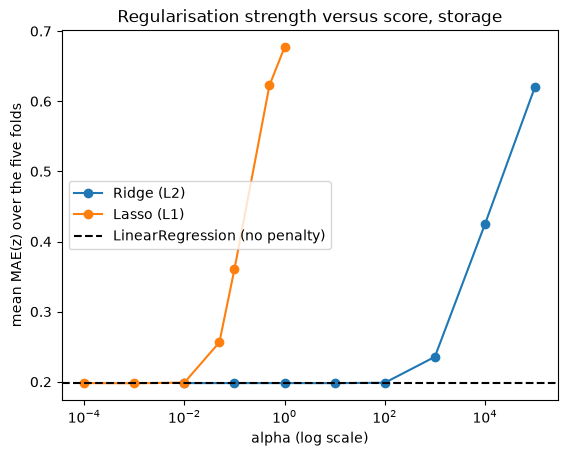

In [15]:
plt.plot(ridge_alphas, ridge_scores, marker="o", label="Ridge (L2)")
plt.plot(lasso_alphas, lasso_scores, marker="o", label="Lasso (L1)")
plt.axhline(ols_mean, color="black", linestyle="--", label="LinearRegression (no penalty)")
plt.xscale("log")
plt.xlabel("alpha (log scale)")
plt.ylabel("mean MAE(z) over the five folds")
plt.title("Regularisation strength versus score, storage")
plt.legend()
plt.show()

In [16]:
train_idx, val_idx = folds[0]
prep = make_preprocessor()
X_train_prep = prep.fit_transform(X.iloc[train_idx])
print("Shape:", X_train_prep.shape)
print("Rank:", np.linalg.matrix_rank(X_train_prep))
print("Condition number:", round(np.linalg.cond(X_train_prep), 2))

Shape: (9750, 13)
Rank: 13
Condition number: 8.17


**Comparison with the unregularised model.** 
The unregularised LinearRegression has a mean MAE(z) of 0.1981. The best Ridge value tried (alpha = 10) gives 0.1981 and the best Lasso value tried (alpha = 0.001) gives 0.1979. That Lasso gain of about 0.0003 is small beside the fold-to-fold spread of 0.0038 and was picked on the same folds, so it is slightly optimistic. Stronger penalties only make the model worse, slightly at Ridge alpha = 100 and Lasso alpha = 0.01, and clearly from Ridge alpha = 1000 and Lasso alpha = 0.05. Under Lasso, the coefficients driven to exactly zero go from 0 of 13 at alpha = 0.0001 to 5 at alpha = 0.01 and all 13 at alpha = 1, where the model predicts a constant.




**Recommendation, from the shape of the problem.** 
We recommend keeping the unregularised model. The design matrix is narrow relative to the sample: 13 columns against 9,750 training rows in fold 0. Those rows come from only about 1,950 distinct configurations (2,438 across the development table), which is still far more than 13. The matrix has full rank (13) and a low condition number (8.17), so the predictors are not severely collinear and the coefficients are already stable. A penalty has little variance to remove here. The remaining error is more likely bias from the linear form, which a penalty cannot fix.


# P3.5 — Challenge B against Practice 2

In [17]:
#here we're comparing the lineal regression model against the KNN on each fold
#Practice 2 KNN (k=20), MAE(z) per fold, from comparativa.csv
p2_scores = np.array([0.1816, 0.1870, 0.1778, 0.1775, 0.1762])
new_scores = np.array(mae_list)

# positive means the new model did better on that fold
deltas = p2_scores - new_scores

print("P2 KNN:", p2_scores)
print("P3 linear:", np.round(new_scores, 4))
print("Deltas:", np.round(deltas, 4))
print("Mean delta:", round(np.mean(deltas), 4))
print("Std of deltas:", round(np.std(deltas), 4))
print("Std of P2 scores:", round(np.std(p2_scores), 4))
print("Std of new scores:", round(np.std(new_scores), 4))

P2 KNN: [0.1816 0.187  0.1778 0.1775 0.1762]
P3 linear: [0.2047 0.1937 0.1984 0.1953 0.1987]
Deltas: [-0.0231 -0.0067 -0.0206 -0.0178 -0.0225]
Mean delta: -0.0181
Std of deltas: 0.006
Std of P2 scores: 0.0039
Std of new scores: 0.0038


### Why the ordering came out this way

KNN (k = 20) beats LinearRegression on MAE(z) on all five folds. The linear model on z assumes that each predictor adds a fixed amount to z, whatever the other predictors are, while KNN averages similar configurations and so can follow interactions. For example, the effect of iodepth could differ between hdd and nvme. This is our most likely explanation, but we did not test it. KNN’s k was also selected on these same folds, which slightly favours it.

### The six fixed comparison questions

1. **Size and consistency of the change.** Using the five paired differences (descriptive only).

The mean paired difference is −0.0181 in MAE(z), about 10% of the Practice 2 score. The sign is the same on all five folds (−0.0231, −0.0067, −0.0206, −0.0178, −0.0225), so KNN was better on each. The size varies, with a spread of 0.0060. The mean change is larger than the fold-to-fold spread of either model (about 0.004). This is a description of these five folds and we make no claim of statistical significance.




2. **Route and representation.** Pipeline comparison or isolated family comparison, and what the evidence licenses. 

Both rows are on the primary route, but they do not use the same representation: Practice 2 kept every one-hot level, while Practice 3 drops one declared reference level per predictor. The numeric scaling is the same. This is therefore a pipeline comparison, not an isolated family comparison. The evidence supports saying this pipeline did better than that one on these folds. It does not establish that the family alone caused the difference.




3. **What can the new family express** that the previous one could not? 

The linear model gives one global, additive equation. Each coefficient has a direct reading: a multiplicative factor on latency per standard deviation of a numeric predictor, or per level against its declared reference. KNN gives no such summary. In exchange, without added interaction terms the linear model cannot express effects that depend on another predictor, which KNN can follow.






4. **What did it cost** in fitting time, tuning effort and interpretability? 


Fitting time is similar and small: about 0.017 s per fold against 0.013 s for KNN, measured on our machine and therefore only approximate. LinearRegression needs no hyperparameter search, while KNN searched 11 values of k. Ridge and Lasso did add tuning, and it brought almost no improvement. Interpretability improved, but the accuracy on z fell.




5. **Did the ordering of the two challenges' difficulty change**, and why? 

Challenge A (R2): logistic regression gets a mean macro F1 of 0.8381 against 0.9456 for KNN, worse on all five folds. Since the metrics differ, we compare each challenge with its own Dummy. In cyber, KNN closes 94% of the gap to a perfect score and logistic regression 83%. In storage, KNN cuts the Dummy's MAE(z) by 73% and LinearRegression by 71%. The ordering did not change, but the linear model lost much more in cyber (about 11 points against 3). Our untested explanation: some cyber classes overlap in ways a linear boundary cannot separate, while z is close to additive.




6. **Would you ship the new model?** If not, what would change your mind?

Not as a replacement if the goal is the lowest error on z, because KNN was better on all five folds. We would use the linear model when the goal is to explain latency, because it gives readable factors. The picture is not one-sided: on MAE in nanoseconds the linear model is lower (about 16.3 million against 17.2 million), although RMSE(z) and R²(z) favour KNN (0.2703 and 0.8964 against 0.2568 and 0.9065). We would change our mind if interaction terms closed the gap on z, or if the error on the slowest configurations in nanoseconds mattered most.


